### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Alexis Rivera Aguilera

* **Matrícula:** A01840517

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [59]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import json
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy import mean, std
from IPython.display import display
from joblib import Memory
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (make_scorer, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, auc)
from imblearn.metrics import geometric_mean_score, classification_report_imbalanced
import sklearn, imblearn, matplotlib





**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [60]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
# Cargamos los datos del archivo de la actividad:
path ='/content/drive/MyDrive/Trimestre (Septiembre - Diciembre)/Actividad 4 | Problema de Clases No Balanceados: Oil-Spill/oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [62]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) Se usa G-mean porque hay 896 casos sin derrame y 41 con derrame. Predecir siempre «no hay derrame» acierta 95.62% del conjunto completo, aunque omite todos los derrames. Por eso la exactitud puede dar una impresión equivocada.

* 1b) La imagen no contiene un derrame, pero el modelo genera una alerta. Puede provocar una inspección innecesaria, gasto de combustible, horas de trabajo y saturación del equipo. Una mancha de algas podría ser una causa de confusión.

* 1c) Sí existe un derrame, pero el modelo indica que no lo hay. Retrasa la contención, facilita que la contaminación se extienda y puede aumentar los daños ambientales y el costo de limpieza. En el escenario económico posterior es el error más costoso.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [63]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


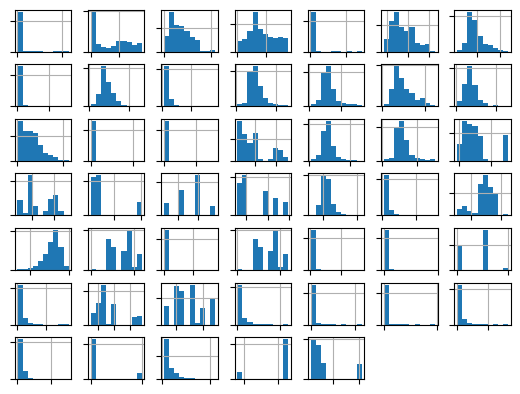

In [64]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [65]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) Yeo-Johnson es una familia de transformaciones de potencia que cambia la escala de cada variable y puede reducir su asimetría. Estima un parámetro lambda para cada columna a partir de los datos de entrenamiento, mediante máxima verosimilitud. Después aplica esa misma transformación a los datos nuevos. Admite valores positivos, negativos y cero.

* 2b) Box-Cox requiere valores estrictamente positivos. Yeo-Johnson puede aplicarse directamente a las variables de esta actividad que contienen ceros o negativos, sin sumarles una constante arbitraria. Ambas buscan estabilizar la variabilidad y mejorar la simetría, y ambas deben ajustarse únicamente con los datos de entrenamiento de cada partición.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [66]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Estrategia y divisiones elegidas. Para G-mean se elige uniform: asigna cada clase con probabilidad 0.5 y proporciona una referencia de azar útil, cercana a 0.5. most_frequent, prior y la constante positiva ignoran una clase y obtienen G-mean cero. stratified respeta la escasa proporción positiva, pero con tan pocos derrames casi nunca coincide con ellos.
Se probaron 3, 5, 7 y 10 divisiones. Con uniform los resultados fueron, respectivamente, 0.5506 ± 0.0669, 0.5081 ± 0.1367, 0.4891 ± 0.0813 y 0.4927 ± 0.1635. Se eligen 3 divisiones porque cada fold de validación conserva 9 o 10 derrames y, en estos ensayos, presenta la menor dispersión. Con 10 divisiones quedan solo 2 o 3 derrames por fold. La decisión prioriza la estabilidad y la cantidad de positivos, no maximizar una puntuación de un modelo que no aprende.

* 3b) El valor empírico a superar es 0.5506, con desviación estándar 0.0669, calculado en nueve folds. La referencia teórica de un predictor binario equiprobable es 0.5 en términos de sus tasas esperadas; el promedio obtenido en muestras pequeñas puede apartarse de ese valor. No debe interpretarse 0.5506 como un límite universal ni como una prueba estadística de subentrenamiento.

* 3c) La estrategia adecuada es most_frequent, que predice siempre cero. En entrenamiento acierta 631/659 = 95.7511%. Su matriz es [[631, 0], [28, 0]]: descarta correctamente 631 casos limpios, pero omite los 28 derrames. Con este control vemos por qué una exactitud alta no basta.
las filas representan la clase real y las columnas la predicción, en orden [0, 1]. Sus posiciones son [[TN, FP], [FN, TP]]. Este «umbral baseline» es una puntuación de referencia para comparar modelos; no es el umbral de probabilidad que se ajustará en el ejercicio 7.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [67]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [68]:
filas_dummy = []
for estrategia in ['most_frequent', 'prior', 'stratified', 'uniform', 'constant']:
    for divisiones in [3, 5, 7, 10]:
        modelo_dummy = DummyClassifier(
            strategy=estrategia, random_state=7,
            constant=1 if estrategia == 'constant' else None
        )
        cv_dummy = RepeatedStratifiedKFold(n_splits=divisiones, n_repeats=3, random_state=7)
        resultado = cross_validate(
            modelo_dummy, Xtrain, ytrain, cv=cv_dummy,
            scoring={'gmean': mi_metrica, 'accuracy': 'accuracy'},
            error_score='raise'
        )
        filas_dummy.append({
            'Estrategia': estrategia, 'Divisiones': divisiones,
            'G-mean media': resultado['test_gmean'].mean(),
            'G-mean std': resultado['test_gmean'].std(),
            'Accuracy media': resultado['test_accuracy'].mean()
        })
tabla_dummy = pd.DataFrame(filas_dummy)
display(tabla_dummy)

,Estrategia,Divisiones,G-mean media,G-mean std,Accuracy media
0,most_frequent,3,0.000000,0.000000,0.957513
1,most_frequent,5,0.000000,0.000000,0.957518
2,most_frequent,7,0.000000,0.000000,0.957511
3,most_frequent,10,0.000000,0.000000,0.957529
4,prior,3,0.000000,0.000000,0.957513
5,prior,5,0.000000,0.000000,0.957518
6,prior,7,0.000000,0.000000,0.957511
7,prior,10,0.000000,0.000000,0.957529
8,stratified,3,0.071309,0.133467,0.932224
9,stratified,5,0.053999,0.137672,0.936776


In [69]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------


mi_estrategia = 'uniform'

mi_nsplits = 3


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))

umbral_gmean = float(np.mean(scores))

print(f"Baseline de G-mean: {umbral_gmean:.4f}")


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.65229372 0.57445626 0.4530905  0.50796707 0.52915026 0.60858062
 0.45201556 0.6172134  0.56061191]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.551, std=(0.067)
Baseline de G-mean: 0.5506


Baseline accuracy en entrenamiento: 95.7511%
Matriz en entrenamiento, filas reales y columnas predichas [0, 1]:
[[631   0]
 [ 28   0]]


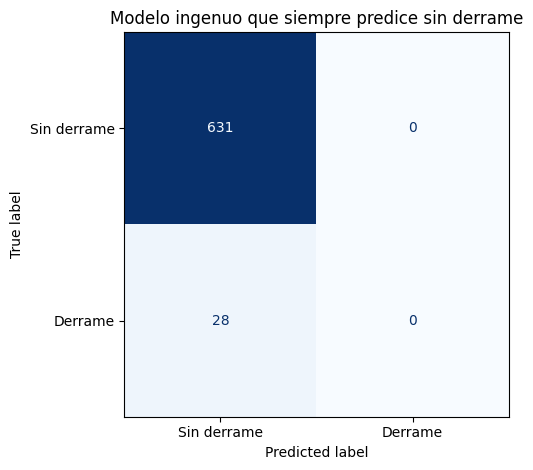

In [70]:
dummy_accuracy = DummyClassifier(strategy='most_frequent', random_state=7)
dummy_accuracy.fit(Xtrain, ytrain)
ytrain_dummy = dummy_accuracy.predict(Xtrain)
baseline_accuracy = accuracy_score(ytrain, ytrain_dummy)
print(f'Baseline accuracy en entrenamiento: {baseline_accuracy:.4%}')
print('Matriz en entrenamiento, filas reales y columnas predichas [0, 1]:')
print(confusion_matrix(ytrain, ytrain_dummy, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(ytrain, ytrain_dummy,
    display_labels=['Sin derrame', 'Derrame'], cmap='Blues', colorbar=False)
plt.title('Modelo ingenuo que siempre predice sin derrame')
plt.tight_layout()
plt.show()

# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



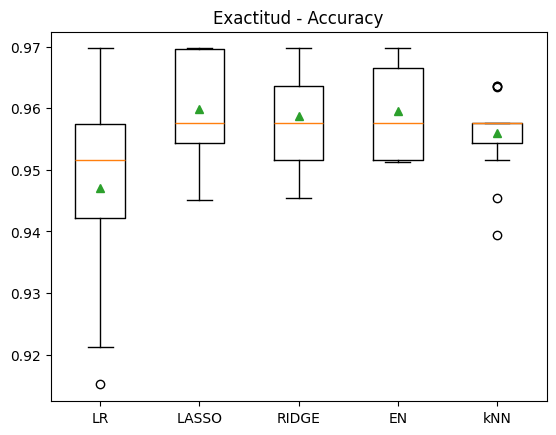

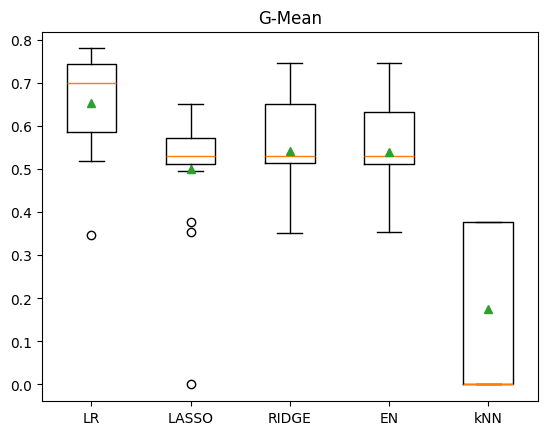

In [71]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




In [72]:
tabla_base = pd.DataFrame({
    'Modelo': nombres,
    'Accuracy media': [np.mean(r) for r in resultados1],
    'Accuracy std': [np.std(r) for r in resultados1],
    'G-mean media': [np.mean(r) for r in resultados2],
    'G-mean std': [np.std(r) for r in resultados2]
})
tabla_base['Supera baseline accuracy'] = tabla_base['Accuracy media'] > baseline_accuracy
tabla_base['Supera baseline G-mean'] = tabla_base['G-mean media'] > umbral_gmean
display(tabla_base)

,Modelo,Accuracy media,Accuracy std,G-mean media,G-mean std,Supera baseline accuracy,Supera baseline G-mean
0,LR,0.947014,0.014735,0.653579,0.118755,False,True
1,LASSO,0.959948,0.008543,0.501118,0.158326,True,False
2,RIDGE,0.958741,0.007722,0.541254,0.113347,True,False
3,EN,0.959544,0.007255,0.540273,0.108520,True,False
4,kNN,0.955910,0.006414,0.174436,0.186566,False,False


### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Respecto a accuracy: LR y kNN no superan el baseline de entrenamiento (95.7511%). Obtienen aproximadamente 94.62% y 95.59%. LASSO, RIDGE y EN lo superan ligeramente, con 95.99%, 95.87% y 95.95%, respectivamente. Según el criterio operativo solicitado, LR y kNN quedan por debajo de la referencia; esto no basta para diagnosticar formalmente subentrenamiento.

* 4b) Respecto a G-mean: con el baseline empírico 0.5506, LASSO, RIDGE, EN y kNN no superan la referencia. Sus medias son 0.5011, 0.5413, 0.5403 y 0.1744. LR sí la supera, con 0.6533, aunque todavía deja margen importante de mejora.
LASSO, RIDGE y EN quedan cerca del azar, y sus distribuciones entre folds se solapan con la referencia. kNN muestra el problema con especial claridad: mucha exactitud y poca detección positiva.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Resultados de los modelos ajustados con la métrica G-mean
LR: G-mean = 0.7542 ± 0.1203
  Parámetros: {'m__class_weight': 'balanced'}
LASSO: G-mean = 0.8373 ± 0.0523
  Parámetros: {'m__C': 0.1, 'm__class_weight': 'balanced'}
RIDGE: G-mean = 0.8173 ± 0.1058
  Parámetros: {'m__C': 0.01, 'm__class_weight': 'balanced'}
EN: G-mean = 0.8416 ± 0.0579
  Parámetros: {'m__C': 0.01, 'm__class_weight': 'balanced', 'm__l1_ratio': 0.25}
kNN: G-mean = 0.1991 ± 0.1863
  Parámetros: {'m__n_neighbors': 3, 'm__p': 2, 'm__weights': 'uniform'}


,Modelo,G-mean media,G-mean std,Mejores parámetros
0,LR,0.754194,0.120299,{'m__class_weight': 'balanced'}
1,LASSO,0.837329,0.052344,"{'m__C': 0.1, 'm__class_weight': 'balanced'}"
2,RIDGE,0.817304,0.105832,"{'m__C': 0.01, 'm__class_weight': 'balanced'}"
3,EN,0.841573,0.057890,"{'m__C': 0.01, 'm__class_weight': 'balanced', ..."
4,kNN,0.199071,0.186295,"{'m__n_neighbors': 3, 'm__p': 2, 'm__weights':..."


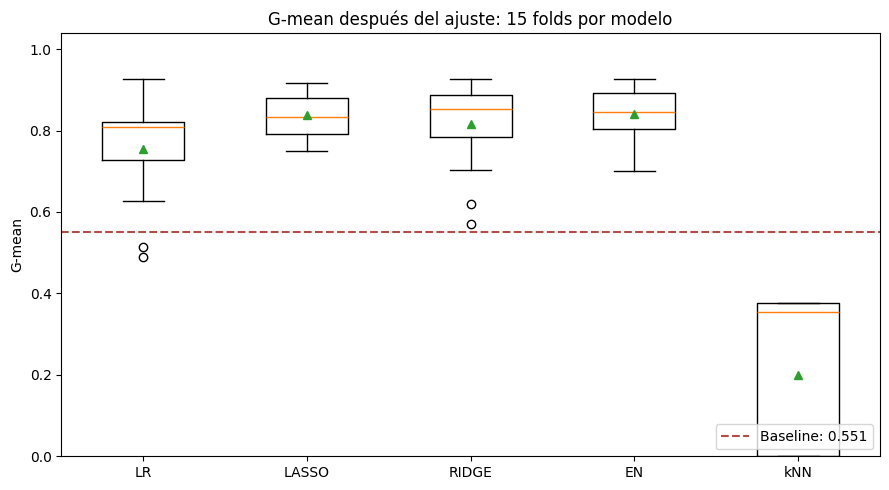

In [73]:
# 5)



print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.



def mis_modelos_ajustados():
    modelos = [
        LogisticRegression(penalty=None, max_iter=20000, random_state=1),
        LogisticRegression(penalty='l1', solver='liblinear', max_iter=20000, random_state=1),
        LogisticRegression(penalty='l2', solver='lbfgs', max_iter=20000, random_state=1),
        LogisticRegression(penalty='elasticnet', solver='saga', max_iter=20000,
                           tol=1e-3, random_state=1),
        KNeighborsClassifier()
    ]
    nombres = ['LR', 'LASSO', 'RIDGE', 'EN', 'kNN']
    rejillas = [
        {'m__class_weight': [None, 'balanced']},
        {'m__C': [0.001, 0.01, 0.1, 1, 10], 'm__class_weight': [None, 'balanced']},
        {'m__C': [0.001, 0.01, 0.1, 1, 10], 'm__class_weight': [None, 'balanced']},
        {'m__C': [0.001, 0.01, 0.1, 1], 'm__class_weight': [None, 'balanced'],
         'm__l1_ratio': [0.25, 0.5, 0.75]},
        {'m__n_neighbors': [3, 5, 9, 15, 21],
         'm__weights': ['uniform', 'distance'], 'm__p': [1, 2]}
    ]
    return modelos, nombres, rejillas

modelos_ajustados, nombres_ajustados, rejillas = mis_modelos_ajustados()
cv_ajuste = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
cache_temporal = tempfile.TemporaryDirectory(prefix='oil_spill_')
memoria = Memory(cache_temporal.name, verbose=0)
busquedas, resultados_ajustados, filas_ajustadas = {}, [], []

print('Resultados de los modelos ajustados con la métrica G-mean')
for nombre, modelo, rejilla in zip(nombres_ajustados, modelos_ajustados, rejillas):
    pipeline_ajuste = Pipeline([('ct', clone(columnasTransformer)), ('m', modelo)],
                              memory=memoria)
    busqueda = GridSearchCV(
        pipeline_ajuste, param_grid=rejilla, scoring=mi_metrica,
        cv=cv_ajuste, n_jobs=1, return_train_score=True, error_score='raise'
    )
    busqueda.fit(Xtv, np.ravel(ytv))
    busquedas[nombre] = busqueda
    indice = busqueda.best_index_
    puntuaciones = np.array([
        busqueda.cv_results_[f'split{i}_test_score'][indice]
        for i in range(busqueda.n_splits_)
    ])
    resultados_ajustados.append(puntuaciones)
    filas_ajustadas.append({'Modelo': nombre,
        'G-mean media': puntuaciones.mean(), 'G-mean std': puntuaciones.std(),
        'Mejores parámetros': str(busqueda.best_params_)})
    print(f'{nombre}: G-mean = {puntuaciones.mean():.4f} ± {puntuaciones.std():.4f}')
    print('  Parámetros:', busqueda.best_params_)

tabla_ajustados = pd.DataFrame(filas_ajustadas)
display(tabla_ajustados)
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(resultados_ajustados, tick_labels=nombres_ajustados, showmeans=True)
ax.axhline(umbral_gmean, color='#B44B46', linestyle='--',
           label=f'Baseline: {umbral_gmean:.3f}')
ax.set(title='G-mean después del ajuste: 15 folds por modelo', ylabel='G-mean', ylim=(0, 1.04))
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




,Índice,G-mean CV,G-mean train,G-mean val,Brecha,Cumple,Parámetros
9,9,0.841573,0.855306,0.930721,0.075415,False,"{'m__C': 0.01, 'm__class_weight': 'balanced', ..."
10,10,0.840893,0.809197,0.923852,0.114655,False,"{'m__C': 0.01, 'm__class_weight': 'balanced', ..."
11,11,0.828071,0.812513,0.902932,0.090420,False,"{'m__C': 0.01, 'm__class_weight': 'balanced', ..."
17,17,0.823844,0.870881,0.934137,0.063256,False,"{'m__C': 0.1, 'm__class_weight': 'balanced', '..."
16,16,0.813369,0.905046,0.934137,0.029091,True,"{'m__C': 0.1, 'm__class_weight': 'balanced', '..."
15,15,0.804590,0.904201,0.934137,0.029936,True,"{'m__C': 0.1, 'm__class_weight': 'balanced', '..."
23,23,0.803531,0.924260,0.940931,0.016671,True,"{'m__C': 1, 'm__class_weight': 'balanced', 'm_..."
21,21,0.799356,0.922605,0.940931,0.018326,True,"{'m__C': 1, 'm__class_weight': 'balanced', 'm_..."
22,22,0.798737,0.923433,0.940931,0.017498,True,"{'m__C': 1, 'm__class_weight': 'balanced', 'm_..."
18,18,0.523308,0.534099,0.780433,0.246335,False,"{'m__C': 1, 'm__class_weight': None, 'm__l1_ra..."


Modelo seleccionado: EN
Hiperparámetros seleccionados con la condición de brecha: {'m__C': 0.1, 'm__class_weight': 'balanced', 'm__l1_ratio': 0.5}
G-mean del mejor modelo-Train: 0.9050
G-mean del mejor modelo-Val: 0.9341
Diferencia absoluta: 2.91 puntos porcentuales
Cumple el límite de 3 puntos: True
Exactitud del mejor modelo-Train: 0.8543
Exactitud del mejor modelo-Val: 0.8788
Matriz de confusión en validación:
[[137  20]
 [  0   8]]
Matriz como porcentaje de todas las observaciones de validación:
[[83.03030303 12.12121212]
 [ 0.          4.84848485]]


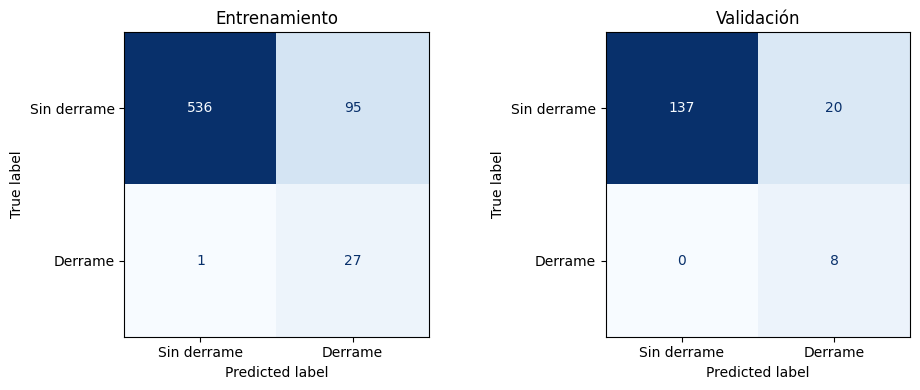

G-mean del mejor modelo-Train: 0.9050
G-mean del mejor modelo-Val: 0.9341

Exactitud del mejor modelo-Train: 0.8543
Exactitud del mejor modelo-Val: 0.8788

Matriz de Confusión con Validación:
 [[137  20]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.83030303 0.12121212]
 [0.         0.04848485]]


In [74]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.


nombre_mejor = max(busquedas, key=lambda nombre: busquedas[nombre].best_score_)
mejor_busqueda = busquedas[nombre_mejor]
filas_candidatas = []
for indice, parametros in enumerate(mejor_busqueda.cv_results_['params']):
    candidato = clone(mejor_busqueda.estimator).set_params(**parametros)
    candidato.fit(Xtrain, np.ravel(ytrain))
    g_train_candidato = geometric_mean_score(ytrain, candidato.predict(Xtrain))
    g_val_candidato = geometric_mean_score(yval, candidato.predict(Xval))
    diferencia = abs(g_train_candidato - g_val_candidato)
    filas_candidatas.append({
        'Índice': indice,
        'G-mean CV': mejor_busqueda.cv_results_['mean_test_score'][indice],
        'G-mean train': g_train_candidato, 'G-mean val': g_val_candidato,
        'Brecha': diferencia, 'Cumple': diferencia <= 0.03,
        'Parámetros': str(parametros)
    })
tabla_candidatas = pd.DataFrame(filas_candidatas)
display(tabla_candidatas.sort_values('G-mean CV', ascending=False))
elegibles = tabla_candidatas.loc[tabla_candidatas['Cumple']]
if elegibles.empty:
    raise ValueError('Ninguna configuración cumple la brecha: se debe ampliar la búsqueda.')
indice_final = int(elegibles.sort_values('G-mean CV', ascending=False).iloc[0]['Índice'])
parametros_finales = mejor_busqueda.cv_results_['params'][indice_final]
mejor_modelo = clone(mejor_busqueda.estimator).set_params(**parametros_finales)
mejor_modelo.set_params(memory=None)
mejor_modelo.fit(Xtrain, np.ravel(ytrain))
ytrain_hat = mejor_modelo.predict(Xtrain)
yval_hat = mejor_modelo.predict(Xval)

gmean_train = geometric_mean_score(ytrain, ytrain_hat)
gmean_val = geometric_mean_score(yval, yval_hat)
brecha = abs(gmean_train - gmean_val)
print('Modelo seleccionado:', nombre_mejor)
print('Hiperparámetros seleccionados con la condición de brecha:', parametros_finales)
print(f'G-mean del mejor modelo-Train: {gmean_train:.4f}')
print(f'G-mean del mejor modelo-Val: {gmean_val:.4f}')
print(f'Diferencia absoluta: {100*brecha:.2f} puntos porcentuales')
print('Cumple el límite de 3 puntos:', brecha <= 0.03)
print(f'Exactitud del mejor modelo-Train: {accuracy_score(ytrain, ytrain_hat):.4f}')
print(f'Exactitud del mejor modelo-Val: {accuracy_score(yval, yval_hat):.4f}')
print('Matriz de confusión en validación:')
print(confusion_matrix(yval, yval_hat, labels=[0, 1]))
print('Matriz como porcentaje de todas las observaciones de validación:')
print(100 * confusion_matrix(yval, yval_hat, labels=[0, 1], normalize='all'))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, real, pred, titulo in zip(axes, [ytrain, yval], [ytrain_hat, yval_hat],
                                 ['Entrenamiento', 'Validación']):
    ConfusionMatrixDisplay.from_predictions(real, pred, ax=ax, colorbar=False,
        display_labels=['Sin derrame', 'Derrame'], cmap='Blues')
    ax.set_title(titulo)
plt.tight_layout()
plt.show()



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
#### Comentario del gráfico curva PR:

* 6b) La exactitud de validación es 87.88%, menor que el aproximadamente 96% de varias variantes del Código-1. El modelo ahora acepta más falsas alarmas entre los muchos casos limpios para detectar los derrames. Como cada caso cuenta igual para accuracy, ese cambio puede disminuirla aunque sea más útil para la tarea. La comparación numérica usa protocolos distintos —un holdout frente a medias cruzadas—, de modo que no se atribuye toda la diferencia exclusivamente a los pesos de clase.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

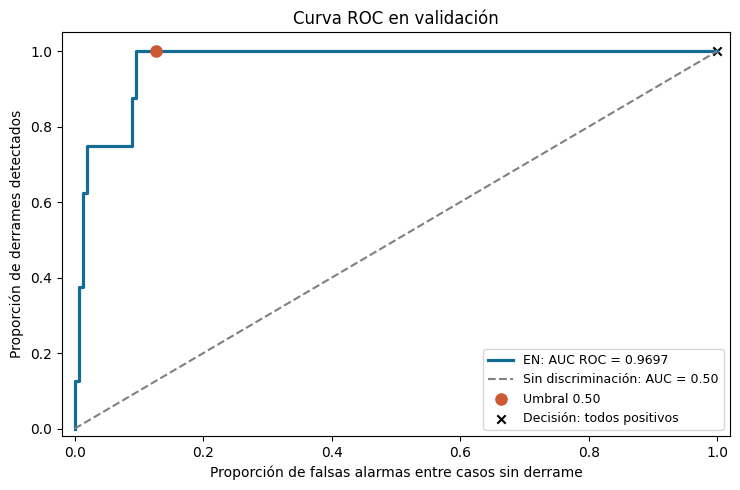

In [75]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**


indice_positivo = list(mejor_modelo.classes_).index(1)
yval_prob = mejor_modelo.predict_proba(Xval)[:, indice_positivo]
fpr, tpr, _ = roc_curve(yval, yval_prob)
auc_roc = roc_auc_score(yval, yval_prob)
auc_roc_ingenuo = roc_auc_score(yval, np.ones(len(yval)))
tn, fp, fn, tp = confusion_matrix(yval, yval_hat, labels=[0, 1]).ravel()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(fpr, tpr, lw=2.3, color='#146C94', label=f'{nombre_mejor}: AUC ROC = {auc_roc:.4f}')
ax.plot([0, 1], [0, 1], '--', color='gray', label=f'Sin discriminación: AUC = {auc_roc_ingenuo:.2f}')
ax.scatter(fp/(fp+tn), tp/(tp+fn), s=65, color='#CA5A34', zorder=3, label='Umbral 0.50')
ax.scatter([1], [1], marker='x', color='black', label='Decisión: todos positivos')
ax.set(xlabel='Proporción de falsas alarmas entre casos sin derrame',
       ylabel='Proporción de derrames detectados', title='Curva ROC en validación',
       xlim=(-0.02, 1.02), ylim=(-0.02, 1.05))
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

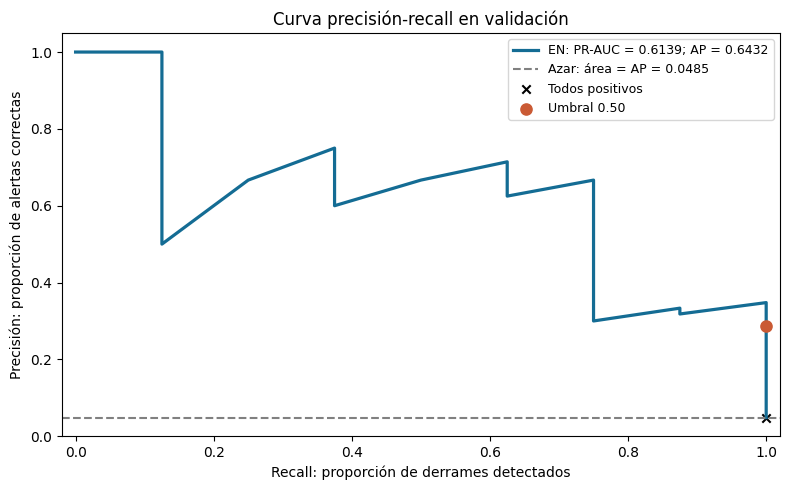

PR-AUC: 0.6139; AP: 0.6432; referencia: 0.0485


In [76]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**


precision_pr, recall_pr, _ = precision_recall_curve(yval, yval_prob)
auc_pr = auc(recall_pr, precision_pr)
ap = average_precision_score(yval, yval_prob)
prevalencia_val = float(np.mean(yval))
ap_ingenuo = average_precision_score(yval, np.ones(len(yval)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall_pr, precision_pr, color='#146C94', lw=2.3,
        label=f'{nombre_mejor}: PR-AUC = {auc_pr:.4f}; AP = {ap:.4f}')
ax.axhline(prevalencia_val, color='gray', linestyle='--',
           label=f'Azar: área = AP = {prevalencia_val:.4f}')
ax.scatter([1], [prevalencia_val], marker='x', color='black', label='Todos positivos')
ax.scatter(tp/(tp+fn), tp/(tp+fp), color='#CA5A34', s=65, zorder=3, label='Umbral 0.50')
ax.set(xlabel='Recall: proporción de derrames detectados',
       ylabel='Precisión: proporción de alertas correctas',
       title='Curva precisión-recall en validación', xlim=(-0.02, 1.02), ylim=(0, 1.05))
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
print(f'PR-AUC: {auc_pr:.4f}; AP: {ap:.4f}; referencia: {ap_ingenuo:.4f}')



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) El modelo obtiene AUC ROC = 0.9697, frente a 0.5 de la referencia sin discriminación. Esto indica que sus puntajes suelen colocar los derrames por encima de los casos limpios. No significa que ese porcentaje de alertas sea correcto.
En la curva PR obtiene PR-AUC = 0.6139 y AP = 0.6432, frente a la referencia 8/165 = 0.0485. El modelo aporta información útil en este conjunto, aunque la precisión cambia con el umbral. Con 0.50, solo 8 de 28 alertas (28.57%) son verdaderos derrames. Esta carga operativa se aprecia mejor con PR que mirando solo ROC.
Para vigilancia ambiental interesa no omitir derrames, pero también evitar inspecciones innecesarias. Por eso el umbral debe relacionarse con los costos y la capacidad de revisión humana. Se observaron cero omisiones en ocho derrames; un solo error cambiaría el recall en 12.5 puntos. Además, validación intervino en el desarrollo. Estos resultados no permiten prometer detección perfecta en nuevas imágenes.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [77]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.87      1.00      0.93      0.93      0.86       157
class 1:oil-spill       0.29      1.00      0.87      0.44      0.93      0.88         8

      avg / total       0.97      0.88      0.99      0.91      0.93      0.86       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





In [78]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

COSTO_FN = 1_000_000
COSTO_FP = 15_000

def evaluar_costos(y_real, probabilidades, umbrales=None,
                   costo_fn=COSTO_FN, costo_fp=COSTO_FP):
    """Costo empírico de cada regla de decisión, usando solo validación."""
    if umbrales is None:
        umbrales = np.round(np.linspace(0.1, 0.9, 81), 2)
    filas = []
    for umbral in umbrales:
        predicciones = (np.asarray(probabilidades) >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, predicciones, labels=[0, 1]).ravel()
        costo_total = int(costo_fn*fn + costo_fp*fp)
        filas.append({'Umbral': float(umbral), 'TN': int(tn), 'FP': int(fp),
                      'FN': int(fn), 'TP': int(tp), 'Costo total USD': costo_total,
                      'Costo por observación USD': costo_total/len(y_real),
                      'G-mean': geometric_mean_score(y_real, predicciones)})
    return pd.DataFrame(filas)

tabla_costos = evaluar_costos(yval, yval_prob)
tabla_costos['Distancia a 0.50'] = abs(tabla_costos['Umbral'] - 0.5)
fila_optima = tabla_costos.sort_values(
    ['Costo total USD', 'FN', 'Distancia a 0.50', 'Umbral']
).iloc[0]
umbral_optimo = float(fila_optima['Umbral'])
costo_optimo = int(fila_optima['Costo total USD'])
fila_original = tabla_costos.loc[np.isclose(tabla_costos['Umbral'], 0.5)].iloc[0]
costo_original = int(fila_original['Costo total USD'])
umbrales_empatados = tabla_costos.loc[
    tabla_costos['Costo total USD'].eq(costo_optimo), 'Umbral'].tolist()
print(f'Umbral seleccionado: {umbral_optimo:.2f}')
print(f'Costo mínimo del lote de validación: USD {costo_optimo:,.0f}')
print('Umbrales con ese mismo costo:', umbrales_empatados)
print('Los 81 resultados de la búsqueda:')
print(tabla_costos.drop(columns='Distancia a 0.50').to_string(index=False))


Umbral seleccionado: 0.59
Costo mínimo del lote de validación: USD 240,000
Umbrales con ese mismo costo: [0.59]
Los 81 resultados de la búsqueda:
 Umbral  TN  FP  FN  TP  Costo total USD  Costo por observación USD   G-mean
   0.10  92  65   0   8           975000                5909.090909 0.765498
   0.11  97  60   0   8           900000                5454.545455 0.786024
   0.12  99  58   0   8           870000                5272.727273 0.794086
   0.13 103  54   0   8           810000                4909.090909 0.809970
   0.14 106  51   0   8           765000                4636.363636 0.821681
   0.15 108  49   0   8           735000                4454.545455 0.829396
   0.16 109  48   0   8           720000                4363.636364 0.833227
   0.17 109  48   0   8           720000                4363.636364 0.833227
   0.18 110  47   0   8           705000                4272.727273 0.837041
   0.19 112  45   0   8           675000                4090.909091 0.844616
   0.20

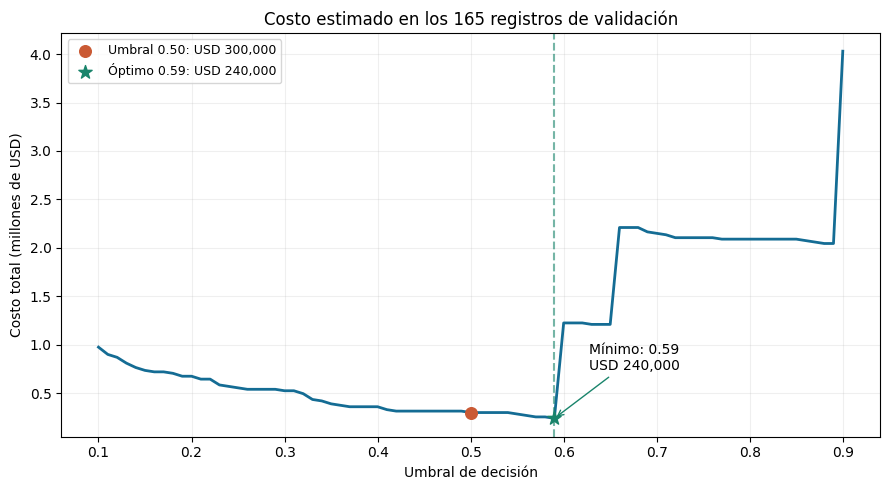

In [79]:
# 7b. Relación entre el umbral y su consecuencia económica.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_costos['Umbral'], tabla_costos['Costo total USD']/1_000_000,
        color='#146C94', lw=2)
ax.scatter([0.5], [costo_original/1_000_000], s=70, color='#CA5A34',
           label=f'Umbral 0.50: USD {costo_original:,.0f}', zorder=3)
ax.scatter([umbral_optimo], [costo_optimo/1_000_000], s=100,
           marker='*', color='#19846B', label=f'Óptimo {umbral_optimo:.2f}: USD {costo_optimo:,.0f}', zorder=4)
ax.axvline(umbral_optimo, color='#19846B', linestyle='--', alpha=0.6)
ax.annotate(f'Mínimo: {umbral_optimo:.2f}\nUSD {costo_optimo:,.0f}',
            xy=(umbral_optimo, costo_optimo/1_000_000), xytext=(25, 35),
            textcoords='offset points', arrowprops={'arrowstyle': '->', 'color': '#19846B'})
ax.set(xlabel='Umbral de decisión', ylabel='Costo total (millones de USD)',
       title='Costo estimado en los 165 registros de validación')
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

,Umbral,TN,FP,FN,TP,Costo total USD,Costo por observación USD,G-mean
Original,0.50,137.0,20.0,0.0,8.0,300000.0,1818.181818,0.934137
Costo mínimo,0.59,141.0,16.0,0.0,8.0,240000.0,1454.545455,0.947676


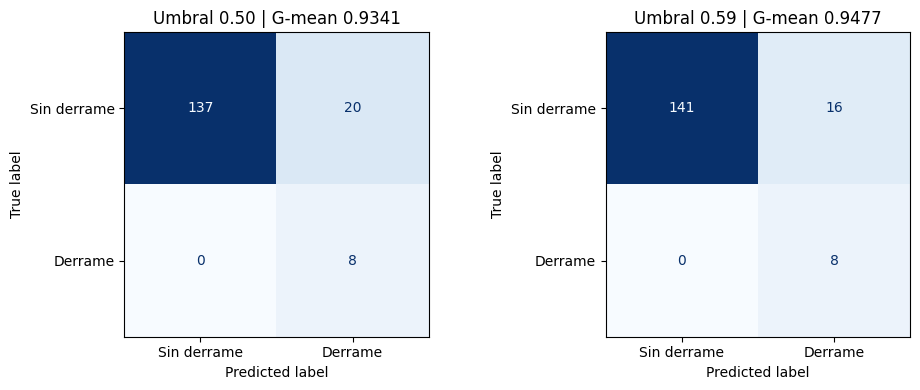

In [80]:
# 7c. Comparar ambas reglas con el mismo modelo y los mismos registros.
yval_hat_optimo = (yval_prob >= umbral_optimo).astype(int)
comparacion_umbrales = pd.DataFrame([fila_original, fila_optima])
comparacion_umbrales.index = ['Original', 'Costo mínimo']
display(comparacion_umbrales.drop(columns='Distancia a 0.50'))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, umbral in zip(axes, [yval_hat, yval_hat_optimo], [0.5, umbral_optimo]):
    ConfusionMatrixDisplay.from_predictions(yval, pred, ax=ax, colorbar=False,
        display_labels=['Sin derrame', 'Derrame'], cmap='Blues')
    ax.set_title(f'Umbral {umbral:.2f} | G-mean {geometric_mean_score(yval, pred):.4f}')
plt.tight_layout()
plt.show()

#7d: decisión de despliegue

En esta búsqueda conviene cambiar 0.50 por 0.59, como configuración candidata para confirmar posteriormente. El umbral aumenta porque los ocho derrames observados conservan puntajes por encima de él y se descartan cuatro falsas alarmas. Un costo elevado de FN no obliga siempre a bajar el umbral: la elección depende también de los puntajes observados.

El costo disminuye USD 60,000 (20%) en los mismos 165 registros. La precisión mejora de 28.57% a 33.33%. El mínimo corresponde a la malla evaluada, no a todos los valores reales posibles. Se probaron solo umbrales entre 0.10 y 0.90, como pide la actividad.
Un FN cuesta lo mismo que unas 66.7 falsas alarmas con los supuestos dados. Si el cambio provocara una omisión adicional, el ahorro de cuatro inspecciones no la compensaría. Como se eligió el umbral con estos mismos datos, el ahorro es una estimación optimista que requiere confirmarse en datos nuevos. Los puntajes de un modelo entrenado con pesos balanceados tampoco se deben interpretar automáticamente como probabilidades calibradas del mundo real.

#7e: Uso de LLM y transparencia

Se utilizó ChatGPT (OpenAI), asistente Codex, en esta conversación.
El promt utilizado fue:

Con yval, las probabilidades de la clase 1 obtenidas de mejor_modelo y sin utilizar prueba, escribe una función de Python que evalúe umbrales entre 0.10 y 0.90 con paso 0.01. Para cada uno cuenta TN, FP, FN y TP; calcula costo total = 1,000,000 × FN + 15,000 × FP, costo por observación y G-mean. Devuelve una tabla. Identifica los umbrales de costo mínimo y usa como desempate menos FN y mayor cercanía a 0.50. Grafica costo total frente al umbral, destaca el mínimo y compara su matriz de confusión con la de 0.50. Explica por qué el costo de validación no garantiza el costo futuro.

El código se ejecutó y las conclusiones se redactaron a partir de sus salidas, no de resultados hipotéticos proporcionados por el LLM.

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* Recomiendo utilizar el modelo para priorizar la revisión de imágenes y conservar a los analistas. Una exactitud de 96% no demuestra que detecte derrames: en nuestra base, responder siempre «no hay derrame» acertaría 95.62% de las veces y dejaría pasar los 41 casos de contaminación. Por tanto, ese indicador no justifica despedir personal ni autorizar envíos automáticos de helicópteros.
Las dos equivocaciones tienen consecuencias distintas. Una falsa alarma moviliza recursos sin necesidad y cuesta 15,000 USD según el escenario. Omitir un derrame retrasa la contención y puede generar un costo de 1,000,000 USD. En los 165 registros de validación, el sistema ingenuo habría omitido los ocho derrames, equivalentes a 8,000,000 USD bajo esos supuestos.
Nuestro modelo detectó los ocho derrames observados. Con su regla inicial generó 20 falsas alarmas, para un costo estimado de 300,000 USD. Al ajustar la sensibilidad de la alerta con los mismos registros, las falsas alarmas bajaron a 16, sin omisiones observadas, y el costo quedó en 240,000 USD. La reducción fue de 20%. Sin embargo, todavía solo 8 de 24 alertas correspondieron a derrames reales. Esto explica por qué sigue siendo necesaria la revisión humana.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

1. La métrica debe responder al problema. Con 41 derrames entre 937 registros, una exactitud cercana a 96% puede acompañar una detección nula. G-mean incorpora el reconocimiento de ambas clases y permite comparar mejor los modelos en la primera etapa.

2. El preprocesamiento debe aprenderse donde corresponde. Yeo-Johnson y la estandarización se aplicaron dentro de cada pipeline. Se mantuvieron las semillas y las particiones de la consigna, sin entrenar transformaciones con prueba.

3. Los valores predeterminados son un punto de partida. La búsqueda de pesos y regularización mejoró sustancialmente las variantes logísticas. La mayor media del ejercicio 5 fue 0.8416; la configuración final se eligió además bajo la condición de diferencia máxima de tres puntos.

4. Se cumplió la comprobación solicitada, con límites claros. Elastic Net obtuvo G-mean de 0.9050 en entrenamiento y 0.9341 en validación: una diferencia de 2.91 puntos. Esto no demuestra ausencia de sobreajuste ni elimina el optimismo de usar validación durante el desarrollo.

5. El umbral es una decisión operativa. Con los costos de la actividad, 0.59 redujo las falsas alarmas de 20 a 16 manteniendo los 8 derrames detectados. El costo estimado del lote pasó de USD 300,000 a USD 240,000. Se distingue este costo observado de una promesa de ahorro futuro.

6. El despliegue requiere revisión humana y evidencia independiente. Se propone mantener a los analistas para confirmar alertas, auditar descartes y autorizar la respuesta. El conjunto Xtest sigue reservado. Antes de desplegar habría que fijar modelo y umbral, realizar una evaluación final independiente y ampliar la validación por imágenes o lotes, pues cinco derrames de prueba seguirían siendo pocos.


### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**